### Import library

In [212]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

%store -r cache_path

df = pd.read_csv(cache_path + "/train.csv")

### View data on table

In [194]:
# Display the first 5 examples
df.head()

,passengerid,homeplanet,cryosleep,cabin,destination,age,vip,roomservice,foodcourt,shoppingmall,spa,vrdeck,name,transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


### Quickly do a basic exploration of the dataset

In [ ]:
df.describe()

In [203]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   passengerid   8693 non-null   str    
 1   homeplanet    8693 non-null   str    
 2   cryosleep     8693 non-null   bool   
 3   cabin         8693 non-null   str    
 4   destination   8693 non-null   str    
 5   age           8693 non-null   float64
 6   vip           8693 non-null   bool   
 7   roomservice   8693 non-null   float64
 8   foodcourt     8693 non-null   float64
 9   shoppingmall  8693 non-null   float64
 10  spa           8693 non-null   float64
 11  vrdeck        8693 non-null   float64
 12  name          8693 non-null   str    
 13  transported   8693 non-null   bool   
dtypes: bool(3), float64(6), str(5)
memory usage: 772.7 KB


In [202]:
df.shape

(8693, 14)

### Initial Inspection and Standardization

**Decision guide based on how much is missing**

| % Missing	 | Recommended Action                              |
|-----------|-------------------------------------------------|
| < 5%      | Drop the rows                                   |
| 5% – 40%  | Fill with median (numbers) or mode (categories) |
| > 40%     | Consider dropping the column                    |

In [213]:
# Step 1: Standardize column names: remove extra spaces, make lower cases,
# replace spaces within the column names with _
df.columns = (df.columns.str.strip().str.lower().str.replace(' ', '_', regex=False))

# Step 2: Handles duplicates value: Check for drop the rows
df.duplicated().sum()

# Remove them
df = df.drop_duplicates()

# Step 3: Handle missing values by following the Decision Guide
print(f"Missing Values per column: \n{df.isnull().sum()}\n")

# Calculate the percentage of missing cell for each rows
df.isnull().mean(axis=1) * 100

Missing Values per column: 
passengerid       0
homeplanet      201
cryosleep       217
cabin           199
destination     182
age             179
vip             203
roomservice     181
foodcourt       183
shoppingmall    208
spa             183
vrdeck          188
name            200
transported       0
dtype: int64



0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
8688    0.0
8689    0.0
8690    0.0
8691    0.0
8692    0.0
Length: 8693, dtype: float64

In [215]:
# Fill missing value
df['age'] = df['age'].fillna(df['age'].median())

money_cols = ['roomservice', 'foodcourt', 'shoppingmall', 'spa', 'vrdeck']
df[money_cols] = df[money_cols].fillna(0)


category_cols = ['homeplanet', 'cryosleep', 'destination', 'vip']
for col in category_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

df['cabin'] = df["cabin"].fillna('Unknown')
df['name'] = df['name'].fillna('Unknown')

# Print result again
print(f'Missing Values per column:\n{df.isnull().sum()}\n')
df.isnull().mean(axis=1) * 100

Missing Values per column:
passengerid     0
homeplanet      0
cryosleep       0
cabin           0
destination     0
age             0
vip             0
roomservice     0
foodcourt       0
shoppingmall    0
spa             0
vrdeck          0
name            0
transported     0
dtype: int64



0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
8688    0.0
8689    0.0
8690    0.0
8691    0.0
8692    0.0
Length: 8693, dtype: float64

### Fixing Data Types

In [156]:
df.dtypes

passengerid         str
homeplanet          str
cryosleep          bool
cabin               str
destination         str
age             float64
vip                bool
roomservice     float64
foodcourt       float64
shoppingmall    float64
spa             float64
vrdeck          float64
name                str
transported        bool
dtype: object

In [238]:
obj_columns = ['cryosleep', 'vip']

for col in obj_columns:
    df[col] = df[col].astype('bool')

df.dtypes

passengerid         str
homeplanet          str
cryosleep          bool
cabin               str
destination         str
age             float64
vip                bool
roomservice     float64
foodcourt       float64
shoppingmall    float64
spa             float64
vrdeck          float64
name                str
transported        bool
dtype: object

### Univariate, Bivariate, Multivariate Analysis

a). Univariate

- Univariate analysis means analyzing one variable/column/feature at a time.
- It helps us understand:
    1. Distribution
    2. Frequency
    3. Spread
    4. Outliers

i) Numerical Columns

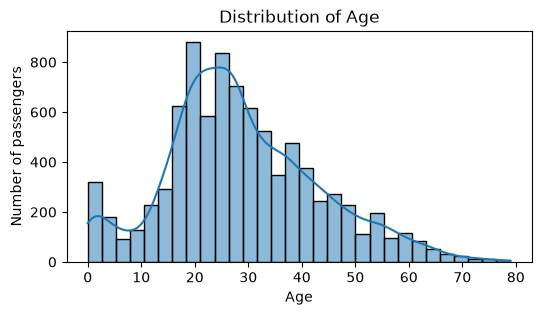

In [289]:
# What is the distribution of age?
plt.figure(figsize=(6, 3))

sns.histplot(data=df, x="age",
             bins=30, kde=True)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.show()

The AGE distribution is concentrate around 20-40 years old, with fewer passengers at the extremes. The distribution appears slightly right-skewed.

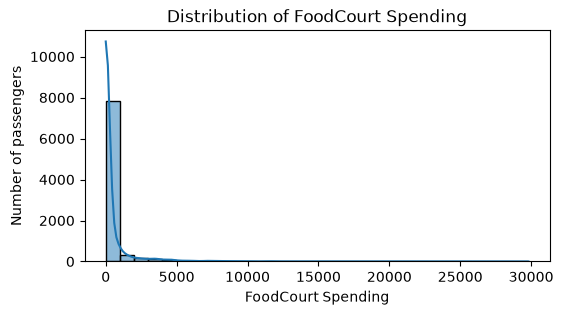

In [287]:
# What is the distribution of FoodCourt spending?
plt.figure(figsize=(6, 3))

sns.histplot(data=df, x="foodcourt",
             bins=30, kde=True)

plt.title("Distribution of FoodCourt Spending")
plt.xlabel("FoodCourt Spending")
plt.ylabel("Number of passengers")
plt.show()

FoodCourt Spending is concentrate at low Spending with most passengers. The distribution is also slightly right-skewed.

ii) Categorical data

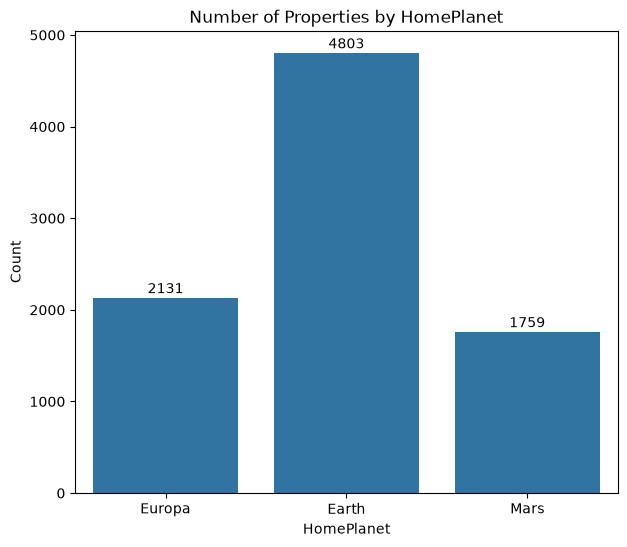

In [284]:
# Counts of HomePlanet
plt.figure(figsize=(7, 6))

ax = sns.countplot(data=df, x='homeplanet')

plt.title('Number of Properties by HomePlanet')
plt.xlabel('HomePlanet')
plt.ylabel('Count')

for rect in ax.patches:
    y_value = rect.get_height()
    x_value = rect.get_x() + rect.get_width() / 2
    space = 1
    label = "{:.0f}".format(y_value)
    plt.annotate(label, (x_value, y_value), xytext=(0, space), textcoords="offset points", ha='center', va='bottom')

plt.show()

The Earth is most passengers all of them, follow by Mars and Europa has the fewest passengers

b). Bivariate Analysis

- Bivariate analysis means analyzing the relationship between two variables.
- It helps us understand:
    1. Relationships.
    2. Comparisons.
    3. Association.
    4. Correlation.
    5. Difference between groups.

i) Numerical vs Numerical

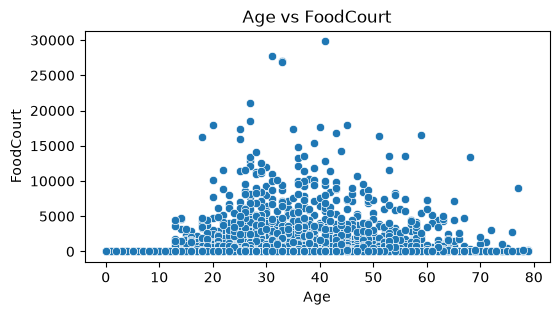

In [269]:
# Age vs FoodCourt
plt.figure(figsize=(6, 3))

sns.scatterplot(df, x="age", y="foodcourt")

plt.title("Age vs FoodCourt")
plt.xlabel("Age")
plt.ylabel("FoodCourt")
plt.show()

Most passengers have low FoodCourt spending regardless of age. There is no clear correlation between age and FoodCourt spending.

ii) Numerical vs Categorical

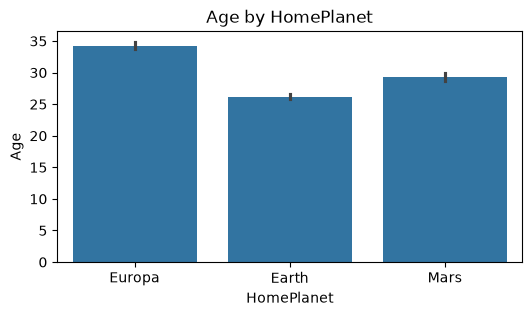

In [268]:
# Age vs HomePlanet
plt.figure(figsize=(6, 3))

sns.barplot(df, x='homeplanet', y='age', estimator='mean')
plt.title('Age by HomePlanet')
plt.xlabel('HomePlanet')
plt.ylabel("Age")
plt.show()

The oldest passengers are mostly from Europa, Mars, and Earth.

iii) Categorical vs Categorical

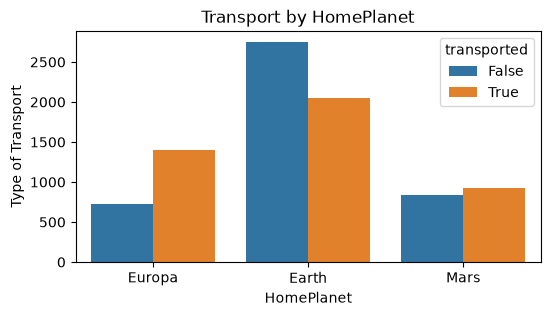

In [271]:
# Transport vs HomePlanet
plt.figure(figsize=(6, 3))

sns.countplot(data=df, x='homeplanet', hue='transported')

plt.title('Transport by HomePlanet')
plt.xlabel('HomePlanet')
plt.ylabel('Number of Transport')
plt.show()

Europa has more transported passengers than non-transported passengers. In contrast, Earth has more non-transported passengers, while Mars has a similar number of transported and non-transported passengers.

c). Multivariate
- Multivariate analysis means analyzing three or more variables at the same time.
- it helps us understand more complex relationships.

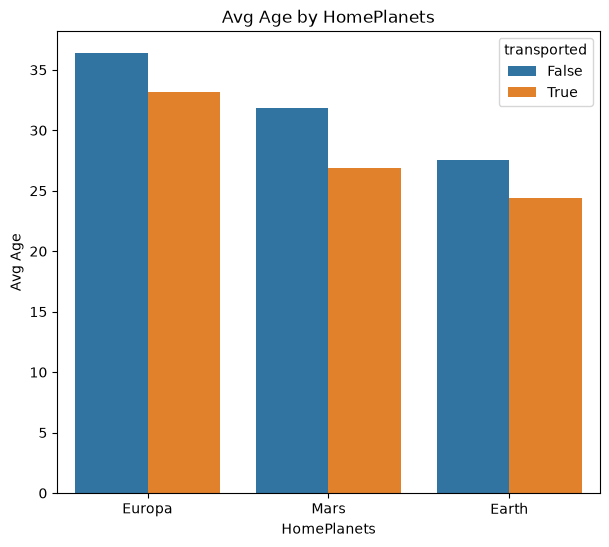

In [277]:
# Avg of age by homePlanet and target on Transport
avg_age_by_homeplanet = df.groupby(['homeplanet', 'transported'])['age'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(7, 6))

sns.barplot(data=avg_age_by_homeplanet, x='homeplanet', y='age', hue='transported')
plt.xlabel('HomePlanets')
plt.ylabel('Avg Age')
plt.title("Avg Age by HomePlanets")
plt.show()

For the oldest passengers across all planets, non-transported passengers outnumber transported passengers.

### Correlation analysis

We use heatmaps to show relationships between numerical variables.
Interpreting correlation

- -1 to -0.5 > Strong negative correlation
- -0.5 to 0 > Weak negative correlation
- 0 to 0.5 > weak positive correlation
- 0.5 to 1 > strong positive

In [274]:
# Select numerical columns
numerical_columns = df.select_dtypes(include=["int", "float"]).columns.to_list()

numerical_columns

['age', 'roomservice', 'foodcourt', 'shoppingmall', 'spa', 'vrdeck']

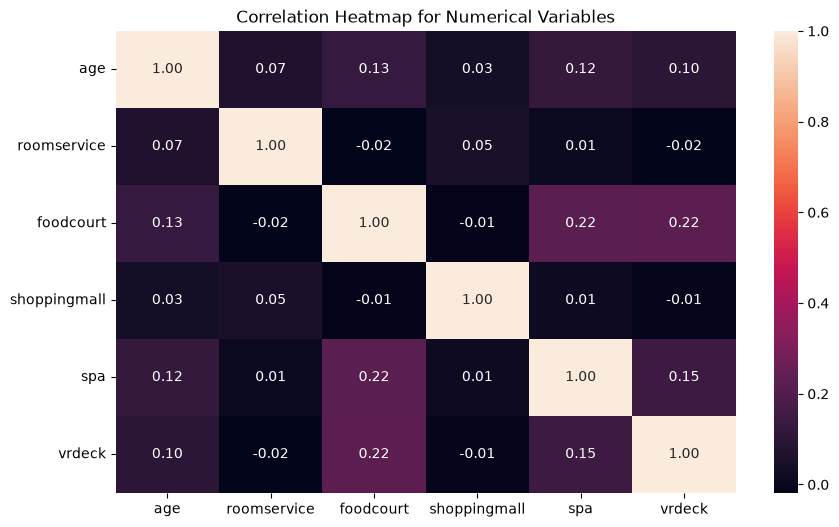

In [275]:
# Correlation analysis
correlation  = df[numerical_columns].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(correlation, annot=True, fmt=".2f")
plt.title("Correlation Heatmap for Numerical Variables")
plt.show()